# CXC101

In [1]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)
from src.utils.ds_helper import get_dataset_distribution


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Load dataset 

In [2]:

load_dotenv()

dataset_path = os.getenv("DATASET_DIR")
train_data_dir = os.path.join(dataset_path, "data03", "train")
test_data_dir = os.path.join(dataset_path, "data03", "test")
val_data_dir = os.path.join(dataset_path, "data03", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data03/train
/Users/joshan/Documents/final-year-project/dataset/data03/test
/Users/joshan/Documents/final-year-project/dataset/data03/val


In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 13028 files belonging to 4 classes.
Found 1527 files belonging to 4 classes.
Found 761 files belonging to 4 classes.


2026-04-02 15:00:18.376749: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-04-02 15:00:18.376787: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-04-02 15:00:18.376791: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-04-02 15:00:18.377124: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-02 15:00:18.377157: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [4]:
# printing dataset distribution 

get_dataset_distribution(
    dir_paths=[
        train_data_dir, 
        test_data_dir, 
        val_data_dir
    ]
)

╒═══════════╤══════════╤═════════════╤════════════════╤═══════════╤═════════╕
│ Dataset   │   Normal │   Pneumonia │   Tuberculosis │   Unknown │   Total │
╞═══════════╪══════════╪═════════════╪════════════════╪═══════════╪═════════╡
│ Train     │     4667 │        3633 │           3573 │      1155 │   13028 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Test      │      548 │         427 │            417 │       135 │    1527 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Val       │      274 │         213 │            207 │        67 │     761 │
╘═══════════╧══════════╧═════════════╧════════════════╧═══════════╧═════════╛


{'train': {'NORMAL': 4667,
  'PNEUMONIA': 3633,
  'TUBERCULOSIS': 3573,
  'UNKNOWN': 1155},
 'test': {'NORMAL': 548,
  'PNEUMONIA': 427,
  'TUBERCULOSIS': 417,
  'UNKNOWN': 135},
 'val': {'NORMAL': 274, 'PNEUMONIA': 213, 'TUBERCULOSIS': 207, 'UNKNOWN': 67}}

### CNN model Architecture

In [6]:
model = models.Sequential([
    # Preprocessing: Rescale inputs to [0, 1]
    layers.BatchNormalization(),
    
    # First Convolutional Block
    layers.Conv2D(32, (3, 3), activation='sigmoid'),
    layers.MaxPooling2D((2, 2)),
    
    # Second Convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Third Convolutional Block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten and Classify
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5), # Helps prevent overfitting
    layers.Dense(4, activation='softmax') # Softmax for multi-class probability
])

In [7]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10


2026-04-02 15:00:37.047652: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


408/408 ━━━━━━━━━━━━━━━━━━━━ 59s 139ms/step - accuracy: 0.5633 - loss: 1.8879 - val_accuracy: 0.8055 - val_loss: 0.6620
Epoch 2/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 60s 146ms/step - accuracy: 0.7472 - loss: 1.2377 - val_accuracy: 0.8581 - val_loss: 0.5430
Epoch 3/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 59s 145ms/step - accuracy: 0.8123 - loss: 0.6504 - val_accuracy: 0.8541 - val_loss: 0.6481
Epoch 4/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 58s 141ms/step - accuracy: 0.8152 - loss: 0.6767 - val_accuracy: 0.8594 - val_loss: 0.5736
Epoch 5/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 62s 153ms/step - accuracy: 0.8328 - loss: 0.6266 - val_accuracy: 0.8791 - val_loss: 0.5607
Epoch 6/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 57s 141ms/step - accuracy: 0.8348 - loss: 0.6928 - val_accuracy: 0.8817 - val_loss: 0.8659
Epoch 7/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 61s 150ms/step - accuracy: 0.8321 - loss: 0.8799 - val_accuracy: 0.8883 - val_loss: 0.6973
Epoch 8/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 62s 151ms/step - accuracy: 0.8381 - loss: 1.1864 - val

### Save Model

In [10]:
# Save the model
model.save('CXC101.keras')
print("Model saved successfully!")

Model saved successfully!


### Evaluating model against test and validation dataset 

In [11]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.8919 - loss: 1.4810
Test Loss: 1.481041431427002
Test Accuracy: 89.19%


In [ ]:
# evaluated against validation dataset
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.8804 - loss: 1.9997
Test Loss: 1.999721646308899
Test Accuracy: 88.04%


2026-04-02 15:17:29.209632: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


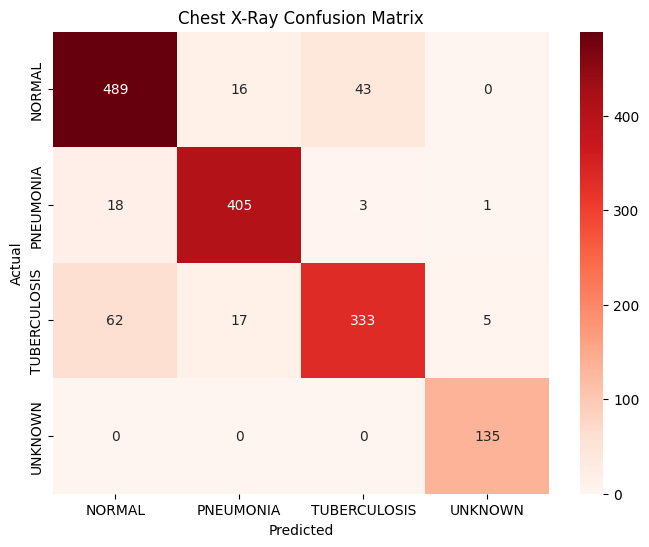

              precision    recall  f1-score   support

      NORMAL       0.86      0.89      0.88       548
   PNEUMONIA       0.92      0.95      0.94       427
TUBERCULOSIS       0.88      0.80      0.84       417
     UNKNOWN       0.96      1.00      0.98       135

    accuracy                           0.89      1527
   macro avg       0.91      0.91      0.91      1527
weighted avg       0.89      0.89      0.89      1527



In [13]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get all predictions and true labels
y_pred = []
y_true = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

# Generate the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = test_ds.class_names

# Plot them in heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Chest X-Ray Confusion Matrix')
plt.show()

# Print precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))